In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer

# Display graphs in the notebook
%matplotlib inline


In [6]:
# Step 1: Import the necessary libraries
import pandas as pd

# Load the cleaned Task 1 data
file_path = "C:/Users/robiti/Desktop/week2/data/cleaned_task1_output.csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("First 5 rows:")
print(df.head())


Dataset loaded successfully!
First 5 rows:
   MSISDN/Number  Dur. (ms)  Total DL (Bytes)  Total UL (Bytes)  \
0   3.360100e+10   116720.0      8.426375e+08        36053108.0   
1   3.360100e+10   181230.0      1.207552e+08        36104459.0   
2   3.360100e+10   134969.0      5.566597e+08        39306820.0   
3   3.360101e+10    49878.0      4.019932e+08        20327526.0   
4   3.360101e+10    37104.0      1.363130e+09        94280527.0   

   Total Volume (Bytes)  
0          8.786906e+08  
1          1.568596e+08  
2          5.959665e+08  
3          4.223207e+08  
4          1.457411e+09  


In [7]:
# Aggregate user engagement metrics: Sessions, Duration, and Traffic
engagement_metrics = df.groupby("MSISDN/Number").agg({
    "Dur. (ms)": "sum",
    "Total DL (Bytes)": "sum",
    "Total UL (Bytes)": "sum"
}).reset_index()

# Rename columns for clarity
engagement_metrics.rename(columns={
    "Dur. (ms)": "Total_Session_Duration",
    "Total DL (Bytes)": "Total_Download_Bytes",
    "Total UL (Bytes)": "Total_Upload_Bytes"
}, inplace=True)

print("Aggregated engagement metrics:")
engagement_metrics.head()


Aggregated engagement metrics:


,MSISDN/Number,Total_Session_Duration,Total_Download_Bytes,Total_Upload_Bytes
0,3.360100e+10,116720.0,8.426375e+08,36053108.0
1,3.360100e+10,181230.0,1.207552e+08,36104459.0
2,3.360100e+10,134969.0,5.566597e+08,39306820.0
3,3.360101e+10,49878.0,4.019932e+08,20327526.0
4,3.360101e+10,37104.0,1.363130e+09,94280527.0


In [8]:
# Top 10 customers per engagement metric
metrics = ["Total_Session_Duration", "Total_Download_Bytes", "Total_Upload_Bytes"]

for metric in metrics:
    print(f"\nTop 10 Users by {metric}:")
    display(engagement_metrics.nlargest(10, metric))



Top 10 Users by Total_Session_Duration:


,MSISDN/Number,Total_Session_Duration,Total_Download_Bytes,Total_Upload_Bytes
36823,3.365973e+10,3539256.0,6.632265e+09,573623884.0
56869,3.366471e+10,2927785.0,6.400774e+09,471244453.0
75815,3.367588e+10,2616081.0,5.300460e+09,398291745.0
59955,3.366553e+10,2598167.0,4.140856e+09,369777784.0
35216,3.365936e+10,2290612.0,4.125428e+09,364377436.0
75658,3.367557e+10,2209198.0,4.019985e+09,318545989.0
39550,3.366037e+10,1945228.0,4.117494e+09,265158857.0
39084,3.366027e+10,1943237.0,3.331324e+09,328891015.0
56987,3.366475e+10,1901398.0,3.356243e+09,350815779.0
14607,3.362833e+10,1708850.0,1.699776e+09,302703100.0



Top 10 Users by Total_Download_Bytes:


,MSISDN/Number,Total_Session_Duration,Total_Download_Bytes,Total_Upload_Bytes
36823,3.365973e+10,3539256.0,6.632265e+09,573623884.0
56869,3.366471e+10,2927785.0,6.400774e+09,471244453.0
75815,3.367588e+10,2616081.0,5.300460e+09,398291745.0
24568,3.365043e+10,771358.0,4.765821e+09,330307342.0
30533,3.365836e+10,1204860.0,4.735096e+09,398892315.0
58674,3.366519e+10,1567208.0,4.622842e+09,366654291.0
61793,3.366617e+10,597600.0,4.469423e+09,302543481.0
85696,3.369876e+10,1113079.0,4.381224e+09,364864791.0
1638,3.360658e+10,1322251.0,4.380586e+09,350881204.0
59302,3.366535e+10,604799.0,4.325772e+09,274710828.0



Top 10 Users by Total_Upload_Bytes:


,MSISDN/Number,Total_Session_Duration,Total_Download_Bytes,Total_Upload_Bytes
36823,3.365973e+10,3539256.0,6.632265e+09,573623884.0
56869,3.366471e+10,2927785.0,6.400774e+09,471244453.0
58264,3.366508e+10,864066.0,3.484241e+09,457112993.0
70473,3.366907e+10,610801.0,3.477886e+09,428655875.0
30533,3.365836e+10,1204860.0,4.735096e+09,398892315.0
75815,3.367588e+10,2616081.0,5.300460e+09,398291745.0
13846,3.362695e+10,1572770.0,3.618609e+09,371768826.0
59955,3.366553e+10,2598167.0,4.140856e+09,369777784.0
58674,3.366519e+10,1567208.0,4.622842e+09,366654291.0
85696,3.369876e+10,1113079.0,4.381224e+09,364864791.0


In [10]:
# Import libraries
from sklearn.preprocessing import MinMaxScaler

# Step 5: Normalize engagement metrics
scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(engagement_metrics[metrics])

# Add normalized data to DataFrame
for i, metric in enumerate(metrics):
    engagement_metrics[f"Normalized_{metric}"] = normalized_data[:, i]

print("Metrics normalized successfully!")
print(engagement_metrics.head())


Metrics normalized successfully!
   MSISDN/Number  Total_Session_Duration  Total_Download_Bytes  \
0   3.360100e+10                116720.0          8.426375e+08   
1   3.360100e+10                181230.0          1.207552e+08   
2   3.360100e+10                134969.0          5.566597e+08   
3   3.360101e+10                 49878.0          4.019932e+08   
4   3.360101e+10                 37104.0          1.363130e+09   

   Total_Upload_Bytes  Normalized_Total_Session_Duration  \
0          36053108.0                           0.031023   
1          36104459.0                           0.049287   
2          39306820.0                           0.036190   
3          20327526.0                           0.012099   
4          94280527.0                           0.008483   

   Normalized_Total_Download_Bytes  Normalized_Total_Upload_Bytes  
0                         0.125888                       0.050731  
1                         0.016899                       0.050822  
2    

Finding optimal number of clusters using Elbow Method...


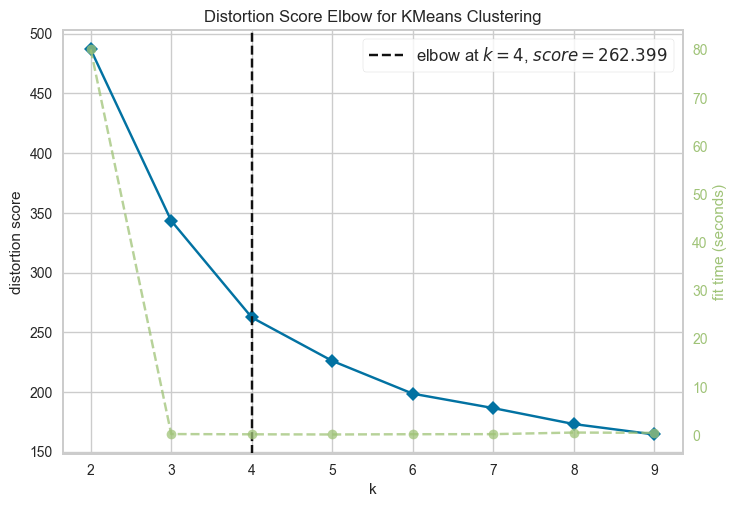

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [13]:
# Import libraries
from sklearn.cluster import KMeans
from yellowbrick.cluster import KElbowVisualizer

# Step 6: Find optimal value of k using Elbow Method
print("Finding optimal number of clusters using Elbow Method...")

model = KMeans()
visualizer = KElbowVisualizer(model, k=(2, 10))

visualizer.fit(normalized_data)
visualizer.show()


In [15]:
from sklearn.cluster import KMeans

# Step 6: Apply K-Means Clustering
print("Applying K-Means clustering with k=3...")

# Convert normalized data to a DataFrame for easy handling
engagement_normalized = pd.DataFrame(normalized_data, columns=metrics)

# Add MSISDN (user ID) back to the normalized DataFrame for reference
engagement_normalized['MSISDN/Number'] = df['MSISDN/Number'].values

# Run K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42)
engagement_normalized['Cluster'] = kmeans.fit_predict(normalized_data)

print("Clustering complete! Sample data:")
print(engagement_normalized.head())


Applying K-Means clustering with k=3...
Clustering complete! Sample data:
   Total_Session_Duration  Total_Download_Bytes  Total_Upload_Bytes  \
0                0.031023              0.125888            0.050731   
1                0.049287              0.016899            0.050822   
2                0.036190              0.082711            0.056477   
3                0.012099              0.059360            0.022962   
4                0.008483              0.204471            0.153552   

   MSISDN/Number  Cluster  
0   3.360100e+10        1  
1   3.360100e+10        1  
2   3.360100e+10        1  
3   3.360101e+10        1  
4   3.360101e+10        0  


In [17]:
# Clean column names (ensure no leading/trailing spaces)
df.columns = df.columns.str.strip()

# Step 8: Aggregate user traffic per application
print("\nAggregating user traffic per application...")
app_columns = ['Social Media DL (Bytes)', 'Google DL (Bytes)', 'Email DL (Bytes)',
               'Youtube DL (Bytes)', 'Netflix DL (Bytes)', 'Gaming DL (Bytes)']

# Verify column names exist
missing_columns = [col for col in app_columns if col not in df.columns]
if missing_columns:
    print(f"Missing columns: {missing_columns}")
else:
    # Group by user ID and aggregate per application
    app_metrics = df.groupby('MSISDN/Number')[app_columns].sum().reset_index()

    # Display top 10 most engaged users per application
    for app in app_columns:
        print(f"\nTop 10 users for {app}:")
        print(app_metrics[['MSISDN/Number', app]].sort_values(by=app, ascending=False).head(10))



Aggregating user traffic per application...
Missing columns: ['Social Media DL (Bytes)', 'Google DL (Bytes)', 'Email DL (Bytes)', 'Youtube DL (Bytes)', 'Netflix DL (Bytes)', 'Gaming DL (Bytes)']


In [19]:
# Step 9: Aggregate total traffic per application and identify most engaged users
print("\nAggregating total traffic per application...")

# Define app columns (use lowercase for consistency)
app_columns = ['social media dl (bytes)', 'google dl (bytes)', 'youtube dl (bytes)']

# Check if all columns exist
missing_cols = [col for col in app_columns if col not in df.columns]
if missing_cols:
    print(f"Missing columns: {missing_cols}")
else:
    # Calculate total traffic per application
    app_traffic = df[app_columns].sum().sort_values(ascending=False)

    # Display results
    print("Total Traffic per Application:")
    print(app_traffic)

    # Find top 10 users for each application
    for app in app_columns:
        print(f"\nTop 10 users for {app.capitalize()}:")
        top_users = df.groupby('msisdn/number')[app].sum().sort_values(ascending=False).head(10)
        print(top_users)



Aggregating total traffic per application...
Missing columns: ['social media dl (bytes)', 'google dl (bytes)', 'youtube dl (bytes)']
